# Extended Data Fig. 3 and Sup. Fig. 4: housekeeping, negative-control and library-size controls
Mouse brain Visium (2,688 spots) scored with EnrichMap (null) and EnrichMap (smoothing-only), the five comparators of
`14_unit_tests` (`score_signatures`) and GSDensity (relevance and antimode labels from `data/gsd_cache/brain` and the R4_F1_GSDensity run).
Sup. Fig. 3: **a** housekeeping contamination of the Pyramidal layer signature, **b** PCA of gene-level weighted contributions,
**c** PanglaoDB absent cell types and the excitatory neuron control (20 genes each, from `ExtendedDataFig3c_signatures`). Sup. Fig. 4: **a** method-to-method Spearman ρ, **b** library-size dependence, also across 50 random 10-gene sets; summary panel.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import json
import pickle

from matplotlib.lines import Line2D
from scipy.stats import spearmanr
from helpers import (
    score_signatures,
    collect_method_scores,
    benchmark_rank_consistency,
    _morans_i_continuous,
    gearys_c_binary,
    stratified_bootstrap_indices,
    auroc_auprc_with_ci,
    spot_call_fractions,
    within_region_spearman,
    gene_contributions_pca_table,
    plot_gene_contributions_pca,
    plot_metric_pair_ci,
    plot_control_score_histograms,
    plot_maps_shared_limits,
    plot_library_size_dependence,
    plot_method_summary_dots,
)

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)
sc.settings.figdir = figure_dir

# processed data directory
processed_data = working_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
}
spot_size = 20

In [6]:
# 1. Load data (01_visium_platform: filter_genes(min_cells=1), normalize_total(1e4), log1p)
adata = sc.read_h5ad(processed_data + "visium_brain_adata.h5ad")
coords = adata.obsm["spatial"]
clusters = adata.obs["cluster"].astype(str).values

# 6-NN graph of em.tl.score, also the Moran's I and Geary's C weights
sq.gr.spatial_neighbors(adata, n_neighs=6, coord_type="generic", key_added="spatial")
conn = adata.obsp["spatial_connectivities"]

# library size as in 17_benchmarking (sum of log1p-normalised expression) and raw UMI counts
lib_size = np.asarray(adata.X.sum(axis=1)).ravel()
total_counts = adata.obs["total_counts"].values.astype(float)
print(f"spots: {adata.n_obs}, genes: {adata.n_vars}")
print(f"library size vs total_counts: ρ = {spearmanr(lib_size, total_counts).correlation:.3f}")

spots: 2688, genes: 18078
library size vs total_counts: ρ = 0.825


In [7]:
# 2. Signatures: region top-10 (01 c11, c13), housekeeping (01 c57), Extended Data Fig. 3c gene sets (ExtendedDataFig3c_signatures), random sets (R4_F1_GSDensity)
cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"
regions = [cell_type_1, cell_type_2]
region_labels = {cell_type_1: "Pyramidal layer", cell_type_2: "Striatum"}

with open(f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)
with open(f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_striatum = pickle.load(f)

region_sets = {
    cell_type_1: signature_dict_pyramidal[f"{cell_type_1}_top10"],
    cell_type_2: signature_dict_striatum[f"{cell_type_2}_top10"],
}

# the 12 symbols of 01 c57 (Hprt1 and Rlp13a are not in the data, so 10 are scored)
housekeeping_genes = ["Gapdh", "Atp5f1", "Ubc", "Pgk1", "Tbp", "Rer1", "Hprt1", "Rpl27", "Rlp13a", "Sdha", "Actb", "B2m"]
hk_sets = {
    cell_type_1: region_sets[cell_type_1],
    "Housekeeping": housekeeping_genes,
    f"{cell_type_1}+Housekeeping": region_sets[cell_type_1] + housekeeping_genes,
}
gs_labels = {cell_type_1: "pyramidal", "Housekeeping": "housekeeping", f"{cell_type_1}+Housekeeping": "combined"}

# Gene sets of Extended Data Fig. 3c (20 genes each, written by ExtendedDataFig3c_signatures) and, for Extended Data Fig. 4b, 50 uniformly
# random 10-gene sets, as used for GSDensity in R4_F1_GSDensity
panglao = json.load(open(working_dir + "data/F1/ED3c_gene_sets.json"))
cell_types = ["Cardiomyocytes", "Embryonic stem cells", "Hepatocytes", "Excitatory neurons"]
ct_titles = ["Cardiomyocyte", "ESC", "Hepatocyte", "Excitatory neuron"]
panglao_sets = {ct: panglao[ct] for ct in cell_types}

f1_sets = json.load(open(working_dir + "data/F1/F1_genesets.json"))
random_sets = {k: v for k, v in f1_sets.items() if k.startswith("random_")}

print(f"housekeeping genes absent from var_names: {[g for g in housekeeping_genes if g not in adata.var_names]}")
for ct, genes in panglao_sets.items():
    print(f"PanglaoDB {ct}: {np.isin(genes, adata.var_names).sum()}/{len(genes)} genes present")
print(f"random sets: {len(random_sets)} x {sorted({len(v) for v in random_sets.values()})} genes")

housekeeping genes absent from var_names: ['Hprt1', 'Rlp13a']
PanglaoDB Cardiomyocytes: 20/20 genes present
PanglaoDB Embryonic stem cells: 20/20 genes present


PanglaoDB Hepatocytes: 20/20 genes present


PanglaoDB Excitatory neurons: 20/20 genes present
random sets: 50 x [10] genes


In [8]:
# 3. EnrichMap: null model (default) and smoothing-only
variants = {"null": dict(compute_q_vals=True)}

gene_sets = {**hk_sets, **panglao_sets, **region_sets, **random_sets}
for name, genes in gene_sets.items():
    for variant, kwargs in variants.items():
        em.tl.score(adata, gene_set=genes, score_key=f"{name}_{variant}", **kwargs)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_null: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.65it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Housekeeping_null: 10/12 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Housekeeping_null: 10/12 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.72it/s]

... (175 outputs left out)

Scoring random_48_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.18it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring random_49_null: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring random_49_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.49it/s]

In [9]:
# 4. Null-model diagnostics (level offset / median null SD > 5: no matched peers; control overlap > 0.10: coarse
# null; neutral spots: no signature or control expression, z = 0 and p = 1)
diagnostics = []
for name, genes in gene_sets.items():
    info = adata.uns["null_model"][f"{name}_null"]
    z = adata.obs[f"{name}_null_score"].values
    diagnostics.append({
        "signature": name,
        "genes scored": int(np.isin(genes, adata.var_names).sum()),
        "level offset ratio": info["level_offset_ratio"],
        "control overlap": info["control_overlap"],
        "fraction neutral spots": np.mean((z == 0) & (info["p_empirical"] == 1)),
    })
null_diagnostics = pd.DataFrame(diagnostics)
is_random = null_diagnostics["signature"].str.startswith("random_")
print(null_diagnostics[~is_random].round(4).to_string(index=False))
print(null_diagnostics[is_random].describe().loc[["50%", "max"]].round(4).to_string())

                   signature  genes scored  level offset ratio  control overlap  fraction neutral spots
             Pyramidal_layer            10              0.0049           0.0178                     0.0
                Housekeeping            10              0.1495           0.0218                     0.0
Pyramidal_layer+Housekeeping            20              0.0476           0.0192                     0.0
              Cardiomyocytes            20              0.0226           0.0184                     0.0
        Embryonic stem cells            20              0.0070           0.0186                     0.0
                 Hepatocytes            20              0.0051           0.0179                     0.0
          Excitatory neurons            20              0.0102           0.0181                     0.0
                    Striatum            10              0.0007           0.0186                     0.0
     genes scored  level offset ratio  control overlap  fraction

In [10]:
# 5. GSDensity: relevance and native antimode labels
for name in [*hk_sets, *panglao_sets, cell_type_2]:
    table = pd.read_csv(working_dir + f"data/gsd_cache/brain/{name.replace(' ', '_')}.csv", index_col=0)
    table = table.reindex(adata.obs_names)
    adata.obs[f"{name}_gsdensity"] = table["relevance"].values
    adata.obs[f"{name}_gsdensity_positive"] = (table["label"] == "positive").values

# random sets: the R4_F1_GSDensity run shared by every brain set
gsd_dir = working_dir + "data/F1/gsd_main/"
gsd_scores = pd.read_csv(gsd_dir + "gsd_scores.csv", index_col=0).reindex(adata.obs_names)
gsd_labels = pd.read_csv(gsd_dir + "gsd_labels.csv", index_col=0).reindex(adata.obs_names)
for name in random_sets:
    adata.obs[f"{name}_gsdensity"] = gsd_scores[name].values
    adata.obs[f"{name}_gsdensity_positive"] = (gsd_labels[name] == "positive").values

In [11]:
# 6. Comparators (score_signatures of 14_unit_tests) and the score tables of each panel
method_keys = {
    "EnrichMap (null)": "{gs}_null_score",
    "AUCell": "{gs}_aucell",
    "GSVA": "{gs}_gsva",
    "ssGSEA": "{gs}_ssgsea",
    "Z score": "{gs}_zscore",
    "Scanpy": "{gs}_scanpy",
    "GSDensity": "{gs}_gsdensity",
}
methods = list(method_keys)
null, smooth = methods[:2]
comparators = ["aucell", "gsva", "ssgsea", "zscore", "scanpy"]

# ssGSEA NES depends on the sets scored together, so each panel is scored and tabulated on its own
score_signatures(adata, hk_sets, methods=comparators)
s3a = collect_method_scores(adata, hk_sets, method_keys)
score_signatures(adata, panglao_sets, methods=comparators)
s3c = collect_method_scores(adata, panglao_sets, method_keys)
score_signatures(adata, region_sets, methods=comparators)
s4 = collect_method_scores(adata, region_sets, method_keys)
score_signatures(adata, random_sets, methods=comparators)
s_rand = collect_method_scores(adata, random_sets, method_keys)

In [12]:
# 7. Sup. Fig. 3a numbers: AUROC/AUPRC for the Pyramidal layer (95% CI over 1,000 stratified spot bootstraps),
# Moran's I, Geary's C and agreement with the clean and the housekeeping score of the same method
y_pyr = (clusters == cell_type_1).astype(int)
boot_pyr = stratified_bootstrap_indices(y_pyr, n_boot=1000, seed=0)

rows = []
for m in methods:
    for gs, lab in gs_labels.items():
        s = s3a[m][gs].values
        row = {
            "method": m,
            "gene set": lab,
            **auroc_auprc_with_ci(y_pyr, s, boot_pyr),
            "Moran's I": _morans_i_continuous(s, conn),
            "Geary's C": gearys_c_binary(s, conn),
            "Spearman ρ vs pyramidal score": spearmanr(s, s3a[m][cell_type_1].values).correlation,
            "Spearman ρ vs housekeeping score": spearmanr(s, s3a[m]["Housekeeping"].values).correlation,
        }
        if m == null:
            p = adata.uns["null_model"][f"{gs}_null"]["p_empirical"]
            row.update({
                "fraction z > 0": np.mean(s > 0),
                "fraction z > 1.96": np.mean(s > 1.96),
                "fraction p_empirical <= 0.05": np.mean(p <= 0.05),
                "Pyramidal layer: fraction z > 1.96": np.mean(s[y_pyr == 1] > 1.96),
                "background: fraction z > 1.96": np.mean(s[y_pyr == 0] > 1.96),
            })
        if m == "GSDensity":
            positive = adata.obs[f"{gs}_gsdensity_positive"].values
            row.update({
                "GSDensity: fraction antimode positive": np.mean(positive),
                "Pyramidal layer: fraction antimode positive": np.mean(positive[y_pyr == 1]),
                "background: fraction antimode positive": np.mean(positive[y_pyr == 0]),
            })
        rows.append(row)
s3a_metrics = pd.DataFrame(rows)

metric_cols = ["AUROC", "AUPRC", "Moran's I", "Geary's C", "Spearman ρ vs pyramidal score", "Spearman ρ vs housekeeping score"]
fractions = [c for c in s3a_metrics.columns if "fraction" in c]

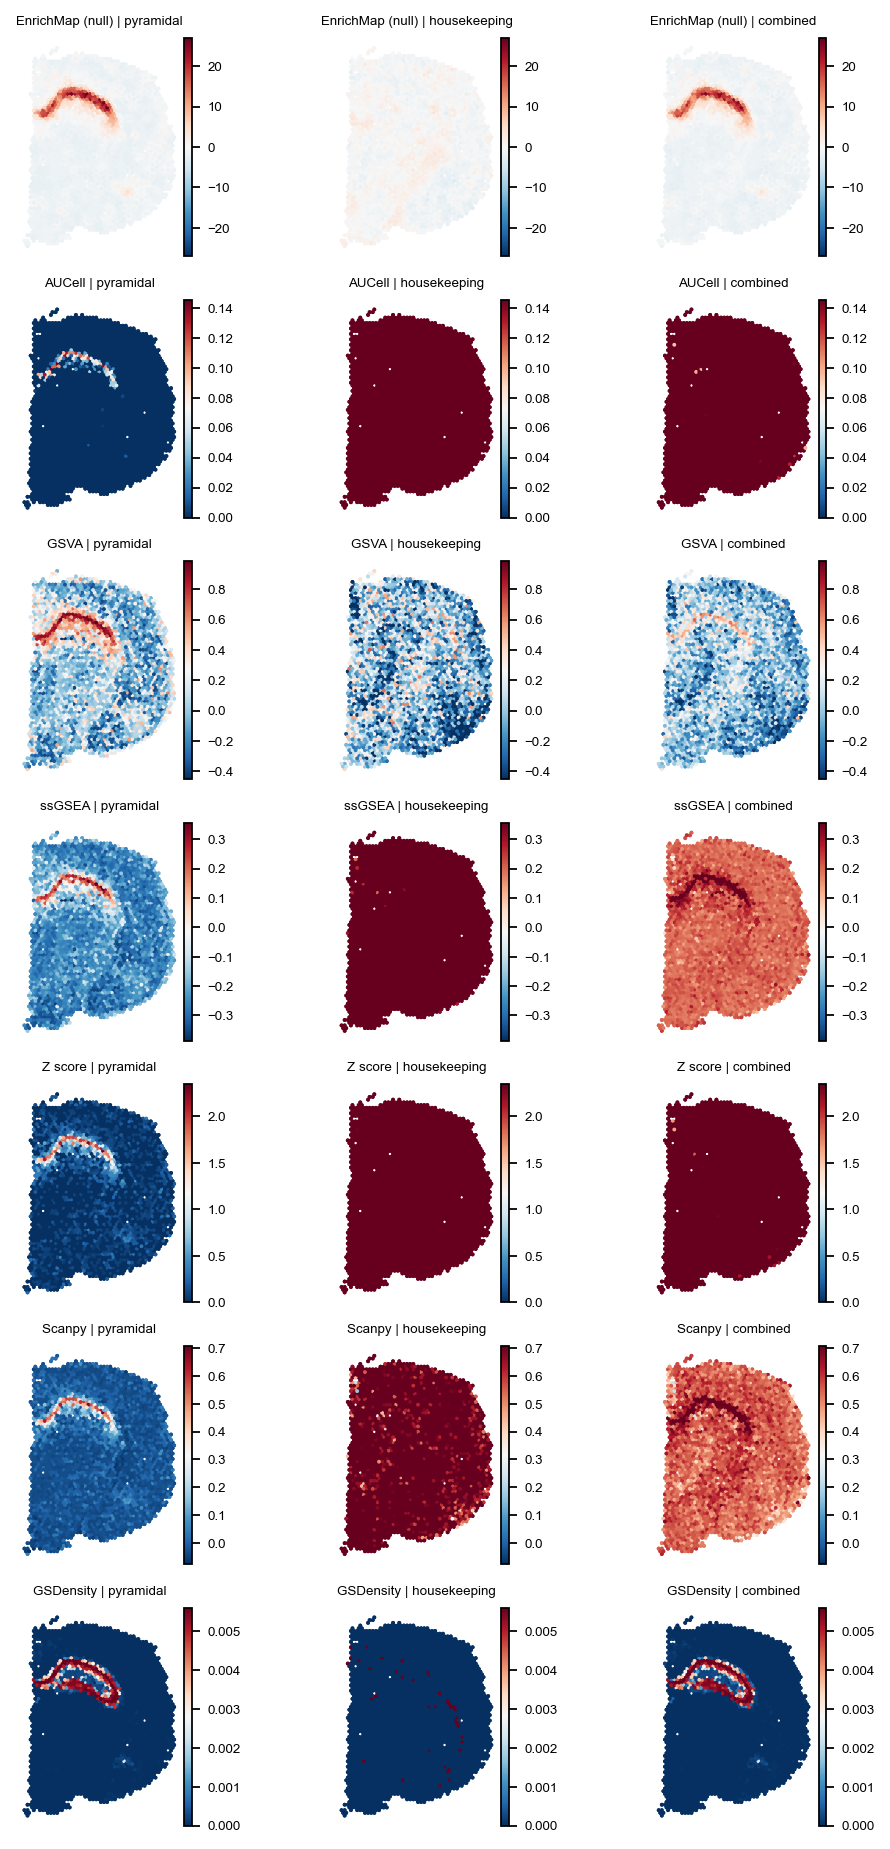

In [13]:
# 8. Extended Data Fig. 3a: EnrichMap (null), the comparators and GSDensity x pyramidal, housekeeping and combined gene
# sets. The three maps of a method share the colour limits of its map of the pyramidal set; EnrichMap (null) is centred at
# 0 and the others run from minimum to maximum
methods_fig = [m for m in methods if "smoothing" not in m]
vcenter_fig = {m: 0 if m == null else None for m in methods_fig}
maps_a = pd.DataFrame({
    "spot_id": adata.obs_names,
    "array_row": adata.obs["array_row"].values,
    "array_col": adata.obs["array_col"].values,
    "x": coords[:, 0],
    "y": coords[:, 1],
    "cluster": clusters,
})
keys = []
for m in methods_fig:
    for gs, lab in gs_labels.items():
        adata.obs[f"{m} | {lab}"] = s3a[m][gs].values
        maps_a[f"{m} | {lab}"] = s3a[m][gs].values
        keys.append(f"{m} | {lab}")

keys_3a = {m: [f"{m} | {lab}" for lab in gs_labels.values()] for m in methods_fig}
reference_3a = {m: f"{m} | {gs_labels[cell_type_1]}" for m in methods_fig}
fig = plot_maps_shared_limits(adata, keys_3a, reference_3a, vcenter=vcenter_fig, size=2.1)
plt.savefig(figure_dir + "ExtendedDataFig3a_housekeeping_maps.pdf", bbox_inches="tight")
plt.show()
maps_a.to_csv(source_dir + "ExtendedDataFig3a_housekeeping_maps.csv", index=False)

In [14]:
# 10. Sup. Fig. 3b: PCA of gene-level weighted contributions (log1p expression x CV weight, computed before
# smoothing and the null model, so the same in both variants)
striatum_hk = region_sets[cell_type_2] + housekeeping_genes
em.tl.score(adata, gene_set=striatum_hk, score_key=f"{cell_type_2}+Housekeeping_null", **variants["null"])
pca_striatum, evr_striatum = gene_contributions_pca_table(
    adata.uns["gene_contributions"][f"{cell_type_2}+Housekeeping_null"], housekeeping_genes
)

# published Pyramidal layer panel: Wilcoxon top-10 + housekeeping)
adata_fs = sq.datasets.visium_hne_adata()
adata_fs.layers["counts"] = adata_fs.raw.X.copy()
adata_fs.X = adata_fs.layers["counts"].copy()

sc.pp.normalize_total(adata_fs, target_sum=1e4)
sc.pp.log1p(adata_fs)
adata_fs.layers["log1p_norm"] = adata_fs.X.copy()
sc.tl.rank_genes_groups(adata_fs, groupby="cluster", method="wilcoxon", layer="log1p_norm", use_raw=False)
gene_set_10 = adata_fs.uns["rank_genes_groups"]["names"][cell_type_1][:10].tolist()
em.tl.score(adata_fs, gene_set=gene_set_10 + housekeeping_genes, score_key="Both_null", **variants["null"])
pca_pyramidal, evr_pyramidal = gene_contributions_pca_table(adata_fs.uns["gene_contributions"]["Both_null"],
                                                            housekeeping_genes)
print(f"first-submission Pyramidal top-10: {gene_set_10}")

# alternative: the Pyramidal layer gene set of panel a (DESeq2 top-10 of the revision, min_cells=1)
pca_pyramidal_a, evr_pyramidal_a = gene_contributions_pca_table(
    adata.uns["gene_contributions"][f"{cell_type_1}+Housekeeping_null"], housekeeping_genes
)

pca_summary = []
for name, df in [("Pyramidal layer (published genes)", pca_pyramidal), ("Striatum", pca_striatum),
                 ("Pyramidal layer (panel a genes)", pca_pyramidal_a)]:
    top = df[df["top_n"]]
    pca_summary.append({
        "PCA": name,
        "genes": len(df),
        "housekeeping genes in top-10": int((top["gene_group"] == "housekeeping").sum()),
        "housekeeping in top-10": ", ".join(top.loc[top["gene_group"] == "housekeeping", "gene"]),
        "median norm, signature": df.loc[df["gene_group"] == "signature", "contribution_norm"].median(),
        "median norm, housekeeping": df.loc[df["gene_group"] == "housekeeping", "contribution_norm"].median(),
    })
print(pd.DataFrame(pca_summary).round(2).to_string(index=False))

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum+Housekeeping_null: 20/22 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum+Housekeeping_null: 20/22 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.45it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Both_null: 20/22 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Both_null: 20/22 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.13it/s]

first-submission Pyramidal top-10: ['Tmsb4x', 'Fibcd1', 'Itpka', 'Hpca', 'Spink8', 'Lefty1', 'Scn3b', 'Rprml', 'Atp2b1', 'Grin2a']
                              PCA  genes  housekeeping genes in top-10               housekeeping in top-10  median norm, signature  median norm, housekeeping
Pyramidal layer (published genes)     20                             1                                  B2m               33.119999                      19.18
                         Striatum     20                             6 B2m, Pgk1, Sdha, Rer1, Atp5f1, Rpl27               16.379999                      19.18
  Pyramidal layer (panel a genes)     20                             2                            B2m, Pgk1               23.940001                      19.18


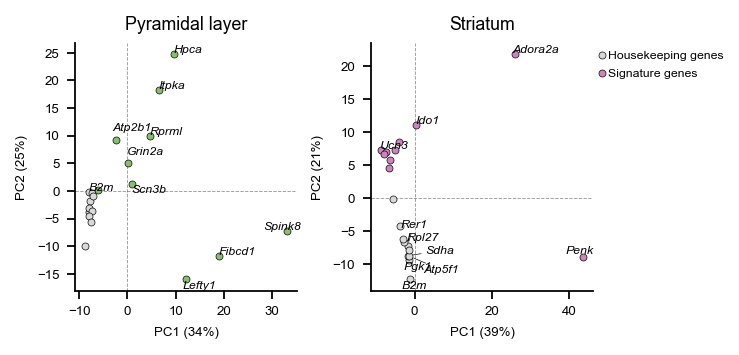

In [15]:
# Extended Data Fig. 3b (score-independent, so one version for both variants)
fig, axes = plt.subplots(1, 2, figsize=(4.6, 2.2))
for ax, (df, evr, title, colour) in zip(axes, [(pca_pyramidal, evr_pyramidal, "Pyramidal layer", "#86bf6e"),
                                               (pca_striatum, evr_striatum, "Striatum", "#cf83bd")]):
    plot_gene_contributions_pca(ax, df, evr, title, {"signature": colour, "housekeeping": "#d9d9d9"})
axes[1].legend(frameon=False, fontsize=5.5, loc="upper left", bbox_to_anchor=(1.0, 1.0), handletextpad=0.2)
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig3b_gene_contributions_pca.pdf", bbox_inches="tight")
plt.show()

pca_b = pd.concat([
    pca_pyramidal.assign(region="Pyramidal layer"),
    pca_striatum.assign(region="Striatum"),
], ignore_index=True)[["region", "gene", "gene_group", "PC1", "PC2", "contribution_norm", "top_n"]]
pca_b.to_csv(source_dir + "ExtendedDataFig3b_gene_contributions_pca.csv", index=False)

In [16]:
# 11. Sup. Fig. 3c numbers: Moran's I, median and IQR of every map; spots called by the null-model rules,
rows = []
for m in methods:
    for ct in cell_types:
        s = s3c[m][ct].values
        rows.append({"method": m, "cell type": ct, "Moran's I": _morans_i_continuous(s, conn),
                     "median": np.median(s), "IQR": np.subtract(*np.percentile(s, [75, 25]))})
s3c_metrics = pd.DataFrame(rows)

rows = []
for ct in cell_types:
    fr = spot_call_fractions(s3c[null][ct].values, adata.uns["null_model"][f"{ct}_null"]["p_empirical"],
                             s3c[smooth][ct].values, adata.obs[f"{ct}_gsdensity_positive"].values)
    rows += [{"gene set": ct, "rule": r, "fraction of spots": v} for r, v in fr.items()]
s3c_calls = pd.DataFrame(rows)
call_rows = list(fr)

calls_table = s3c_calls.pivot(index="rule", columns="gene set", values="fraction of spots").loc[call_rows, cell_types]
print(calls_table.round(3).to_string())
print(s3c_metrics.pivot_table(index="method", columns="cell type", values="Moran's I", sort=False).round(3).to_string())
gsd_kld_3c = pd.read_csv(working_dir + "data/gsd_cache/brain/_tasks/section/gsd_spatial_kld.csv", index_col=0)
print(gsd_kld_3c.loc[[ct.replace(" ", "_") for ct in cell_types], ["delta.kld", "p.adj"]].to_string())

gene set                               Cardiomyocytes  Embryonic stem cells  Hepatocytes  Excitatory neurons
rule                                                                                                        
EnrichMap (null): z > 0                         0.425                 0.401        0.427               0.527
EnrichMap (null): z > 1.96                      0.058                 0.105        0.063               0.427
EnrichMap (null): p_empirical <= 0.05           0.069                 0.118        0.071               0.440
EnrichMap (smoothing-only): score > 0           1.000                 0.761        0.118               0.738
GSDensity: antimode positive                    0.212                 0.099        0.135               0.000
cell type         Cardiomyocytes  Embryonic stem cells  Hepatocytes  Excitatory neurons
method                                                                                 
EnrichMap (null)           0.532                 0.770       

Cardiomyocytes: 0 of 2688 spots at q < 0.05, smallest q = 0.168, 1000 control sets
Embryonic stem cells: 0 of 2688 spots at q < 0.05, smallest q = 0.224, 1000 control sets
Hepatocytes: 0 of 2688 spots at q < 0.05, smallest q = 0.298, 1000 control sets
Excitatory neurons: 1117 of 2688 spots at q < 0.05, smallest q = 0.003, 1000 control sets


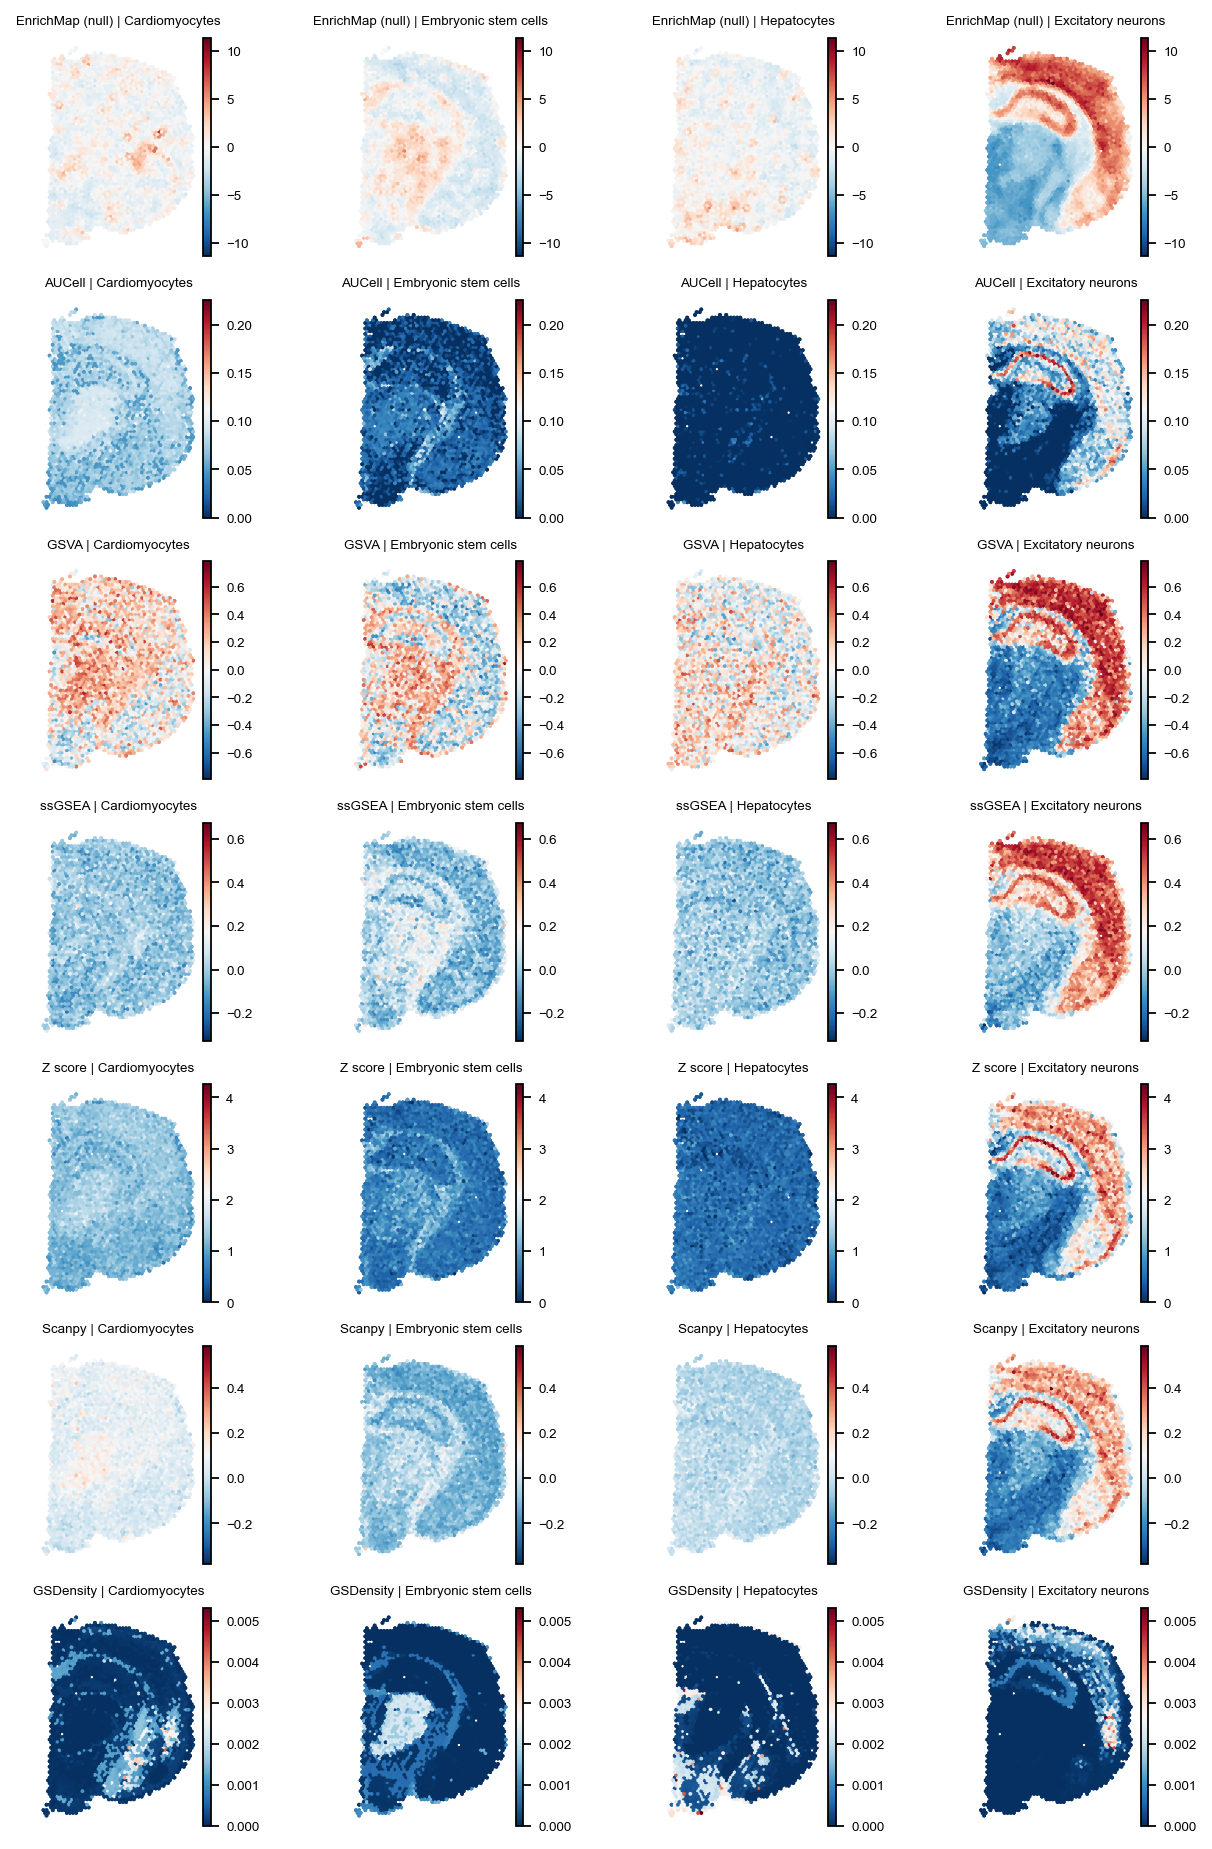

In [17]:
# 12. Extended Data Fig. 3c: absent cell types (PanglaoDB) and the excitatory neuron positive control (Allen). The four maps of a
# method share the colour limits of its map of the positive control (EnrichMap (null): mirrored around 0). Spots at
# q < 0.05 (BH over spots, 1,000 control sets) are drawn in a separate row (next cell)
reference_3c = "Excitatory neurons"
maps_c = maps_a[["spot_id", "array_row", "array_col", "x", "y", "cluster"]].copy()
keys = []
for m in methods_fig:
    for ct in cell_types:
        adata.obs[f"{m} | {ct}"] = s3c[m][ct].values
        maps_c[f"{m} | {ct}"] = s3c[m][ct].values
        keys.append(f"{m} | {ct}")
for ct in cell_types:
    q = adata.obs[f"{ct}_null_q"].values
    adata.obs[f"{null} | {ct}_q"] = q
    maps_c[f"{null} q-value | {ct}"] = q
    maps_c[f"{null} q < 0.05 | {ct}"] = q < 0.05
    print(f"{ct}: {(q < 0.05).sum()} of {adata.n_obs} spots at q < 0.05, smallest q = {q.min():.3f}, "
          f"{adata.uns['null_model'][f'{ct}_null']['n_control_sets']} control sets")



keys_3c = {m: [f"{m} | {ct}" for ct in cell_types] for m in methods_fig}
references_3c = {m: f"{m} | {reference_3c}" for m in methods_fig}
fig = plot_maps_shared_limits(adata, keys_3c, references_3c, vcenter=vcenter_fig, size=2.1)
plt.savefig(figure_dir + "ExtendedDataFig3c_absent_cell_type_maps.pdf", bbox_inches="tight")
plt.show()
maps_c.to_csv(source_dir + "ExtendedDataFig3c_absent_cell_type_maps.csv", index=False)

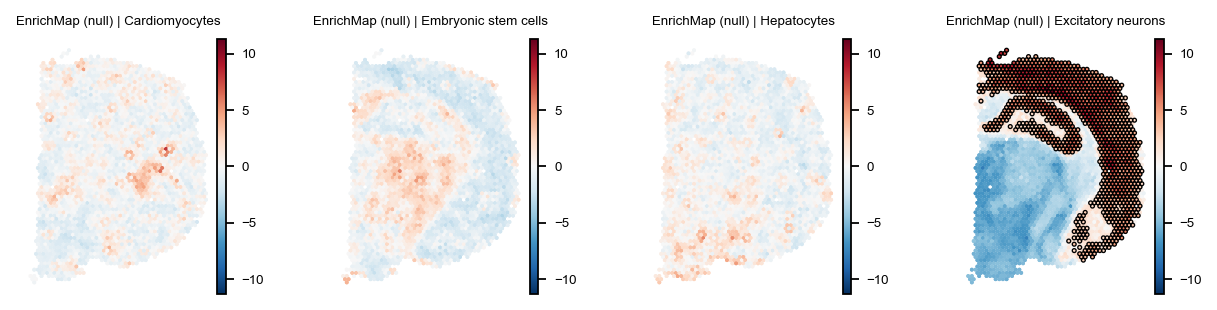

In [18]:
# Extended Data Fig. 3c, EnrichMap (null) maps with black strokes on spots at q < 0.05 (same colour limits as the maps)
fig = plot_maps_shared_limits(adata, {null: keys_3c[null]}, {null: references_3c[null]}, vcenter=vcenter_fig, size=2.1,
                              plot_fdr=[null])
plt.savefig(figure_dir + "ExtendedDataFig3c_EnrichMap_significance_strokes.pdf", bbox_inches="tight")
plt.show()


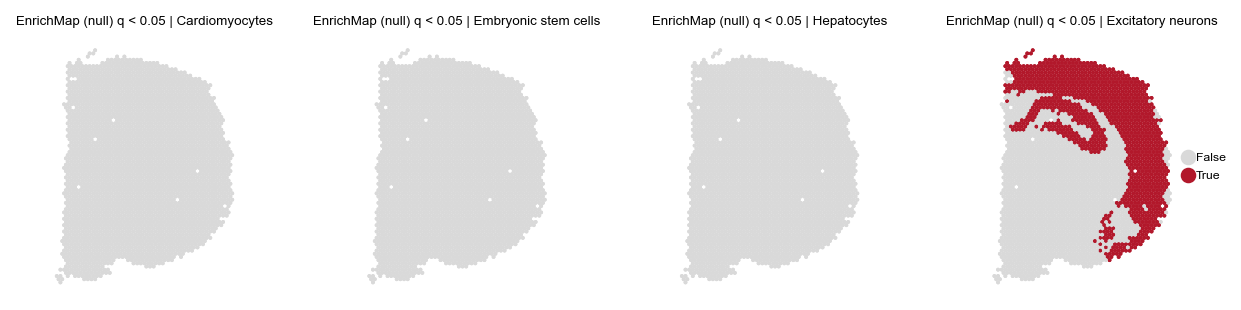

In [19]:
# Extended Data Fig. 3c, row under the EnrichMap (null) maps: spots called significant at q < 0.05 (True / False)
significance_keys = []
for ct in cell_types:
    key = f"{null} | {ct}_significant"
    adata.obs[key] = pd.Categorical(adata.obs[f"{ct}_null_q"].values < 0.05, categories=[False, True])
    adata.uns[f"{key}_colors"] = ["#d9d9d9", "#b2182b"]
    significance_keys.append(key)
fig, axes = plt.subplots(1, len(cell_types), figsize=(2.4 * len(cell_types), 2.1))
for i, (ax, key, ct) in enumerate(zip(axes, significance_keys, cell_types)):
    em.pl.spatial_enrichmap(adata, score_key=key, vcenter=None, shape=None, size=2.1, fig=fig, ax=ax,
                            legend_loc="right margin" if i == len(cell_types) - 1 else None)
    ax.set_title(f"{null} q < 0.05 | {ct}", fontsize=6)
plt.savefig(figure_dir + "ExtendedDataFig3c_significant_spots.pdf", bbox_inches="tight")
plt.show()


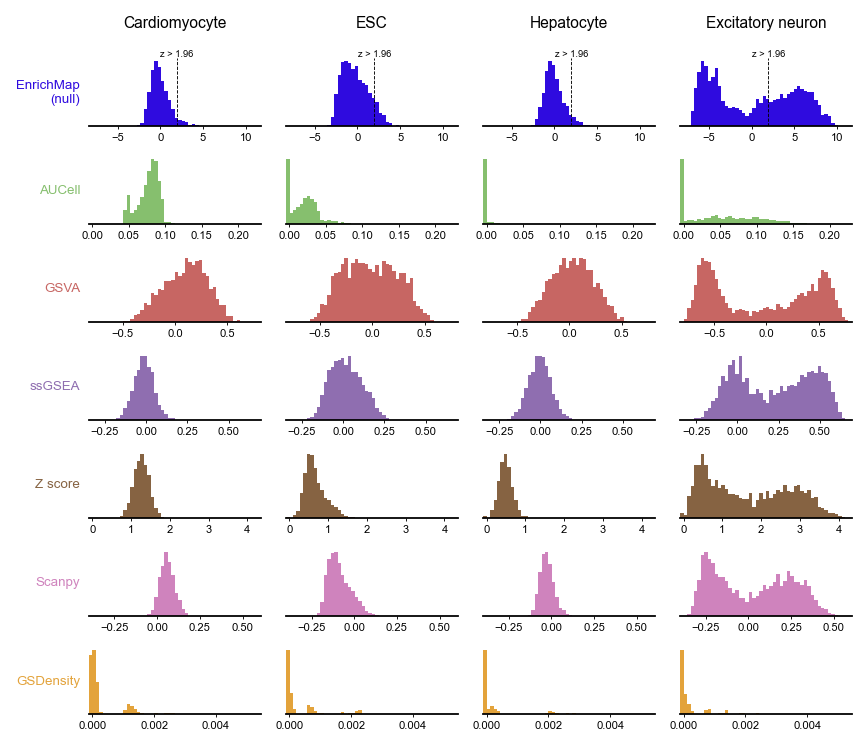

GSDensity | Hepatocytes: 2 spots outside the x axis


In [20]:
# 13. Extended Data Fig. 3c: histograms under the maps (50 bins; x axis of a method = range of its map of the positive control)
fig = plot_control_score_histograms(s3c, cell_types, ct_titles, {m: colours[m] for m in methods_fig}, calls_table,
                                    reference=reference_3c)
plt.savefig(figure_dir + "ExtendedDataFig3c_absent_cell_type_histograms.pdf", bbox_inches="tight")
plt.show()

hist_rows = []
for m in methods_fig:
    ref = s3c[m][reference_3c].values
    pad = 0.02 * (np.nanmax(ref) - np.nanmin(ref))
    edges = np.linspace(np.nanmin(ref) - pad, np.nanmax(ref) + pad, 51)
    for ct in cell_types:
        v = s3c[m][ct].values
        counts, _ = np.histogram(v, bins=edges)
        n_outside = int(((v < edges[0]) | (v > edges[-1])).sum())
        if n_outside:
            print(f"{m} | {ct}: {n_outside} spots outside the x axis")
        for k in range(50):
            hist_rows.append({"method": m, "cell type": ct, "bin": k, "bin_lower": edges[k], "bin_upper": edges[k + 1],
                              "count": counts[k], "spots outside the x axis": n_outside})
pd.DataFrame(hist_rows).to_csv(source_dir + "ExtendedDataFig3c_absent_cell_type_histograms.csv", index=False)

         region           method  mean ρ with comparators  min ρ with comparators  max ρ with comparators  ρ with GSDensity  ρ with EnrichMap (null)  ρ with AUCell
Pyramidal layer EnrichMap (null)                    0.355                   0.323                   0.369             0.495                    1.000          0.323
Pyramidal layer           AUCell                    0.335                   0.319                   0.364             0.413                    0.323          1.000
Pyramidal layer             GSVA                    0.732                   0.319                   0.976             0.440                    0.351          0.319
Pyramidal layer           ssGSEA                    0.731                   0.324                   0.976             0.454                    0.369          0.324
Pyramidal layer          Z score                    0.709                   0.364                   0.897             0.383                    0.363          0.364
Pyramidal layer 

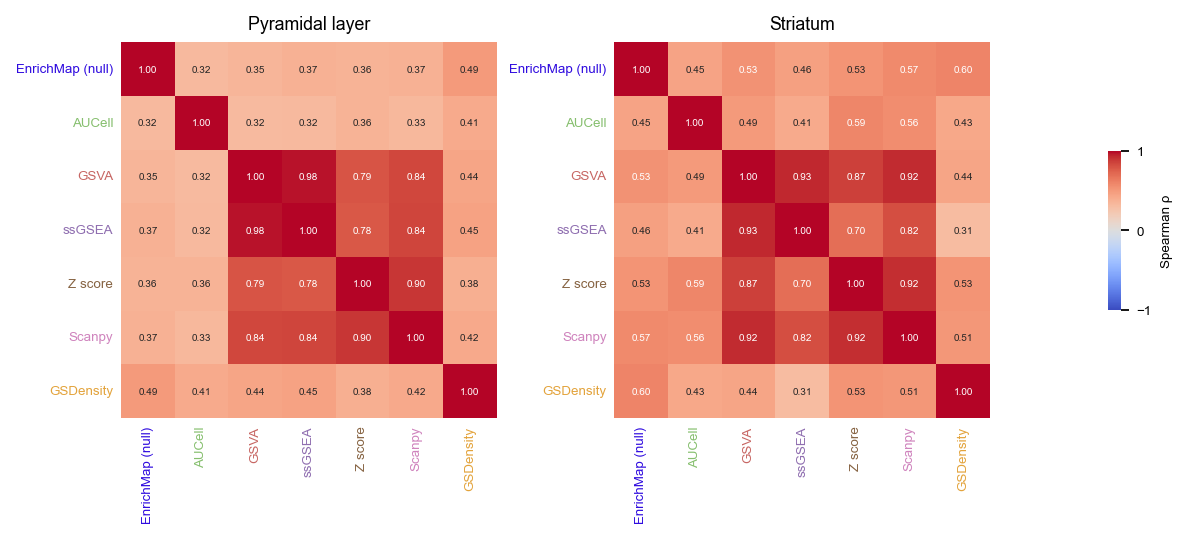

In [21]:
# 15. Sup. Fig. 4a: method-to-method Spearman correlation across spots (17_benchmarking c22)
rank_results = {}
heat_rows = []
for ct in regions:
    for m in methods:
        adata.obs[f"{region_labels[ct]} | {m}"] = s4[m][ct].values
    rank = benchmark_rank_consistency(adata, [f"{region_labels[ct]} | {m}" for m in methods], plot=False)
    rank_results[ct] = pd.DataFrame(rank.values, index=methods, columns=methods)
    for mi in methods:
        for mj in methods:
            heat_rows.append({"region": region_labels[ct], "row_method": mi, "column_method": mj,
                              "spearman_rho": rank_results[ct].loc[mi, mj]})
heat = pd.DataFrame(heat_rows)

# mean correlation of each method with the five comparators (excluding itself) and with GSDensity
comparator_labels = ["AUCell", "GSVA", "ssGSEA", "Z score", "Scanpy"]
rows = []
for ct in regions:
    for m in methods:
        others = [c for c in comparator_labels if c != m]
        rows.append({
            "region": region_labels[ct],
            "method": m,
            "mean ρ with comparators": rank_results[ct].loc[m, others].mean(),
            "min ρ with comparators": rank_results[ct].loc[m, others].min(),
            "max ρ with comparators": rank_results[ct].loc[m, others].max(),
            "ρ with GSDensity": rank_results[ct].loc[m, "GSDensity"],
            f"ρ with {null}": rank_results[ct].loc[m, null],
            f"ρ with {smooth}": rank_results[ct].loc[m, smooth],
        })
print(pd.DataFrame(rows).round(3).to_string(index=False))

# coolwarm and [-1, 1] as in the published panel (a correlation matrix, not a spatial score map)
fig, axes = plt.subplots(1, 3, figsize=(7.4, 3.4), gridspec_kw={"width_ratios": [1, 1, 0.035]})
for ax, ct in zip(axes[:2], regions):
    sns.heatmap(
        rank_results[ct], ax=ax, cmap="coolwarm", vmin=-1, vmax=1, square=True, annot=True, fmt=".2f",
        annot_kws={"fontsize": 4.5}, linewidths=0, cbar=ct == cell_type_2, cbar_ax=axes[2] if ct == cell_type_2 else None,
        cbar_kws={"label": "Spearman ρ", "ticks": [-1, 0, 1]},
    )
    ax.set_title(region_labels[ct], fontsize=8)
    ax.tick_params(labelsize=6, length=0)
    for lab in ax.get_xticklabels() + ax.get_yticklabels():
        lab.set_color(colours[lab.get_text()])
plt.tight_layout()
pos = axes[2].get_position()
axes[2].set_position([pos.x0, pos.y0 + 0.3 * pos.height, pos.width, 0.4 * pos.height])
axes[2].tick_params(labelsize=6)
plt.savefig(figure_dir + "ExtendedDataFig4a_rank_consistency.pdf", bbox_inches="tight")
plt.show()
heat.to_csv(source_dir + "ExtendedDataFig4a_rank_consistency.csv", index=False)

In [22]:
# 16. Sup. Fig. 4b numbers: Spearman ρ with library size over all spots and within regions (>= 30 spots)
truth = "Annotation (truth)"
lib_col = "ρ library size (sum log1p X)"
rows = []
for ct in regions:
    for m in methods + [truth]:
        s = (clusters == ct).astype(float) if m == truth else s4[m][ct].values
        rho, pval = spearmanr(s, lib_size)
        rows.append({
            "region": region_labels[ct],
            "method": m,
            lib_col: rho,
            "p value": pval,
            "ρ total_counts": spearmanr(s, total_counts).correlation,
            "within-region ρ library size": within_region_spearman(s, lib_size, clusters) if m != truth else np.nan,
            "within-region ρ total_counts": within_region_spearman(s, total_counts, clusters) if m != truth else np.nan,
        })
lib = pd.DataFrame(rows)
print(lib.round(3).to_string(index=False))

# null-model mechanism: the matched random sets carry the library-size trend that z removes
for ct in regions:
    info = adata.uns["null_model"][f"{ct}_null"]
    print(f"{region_labels[ct]}: ρ(null mean, library size) = {spearmanr(info['null_mean'], lib_size).correlation:.3f}, "
          f"ρ(null SD, library size) = {spearmanr(info['null_sd'], lib_size).correlation:.3f}")

# random 10-gene sets: any dependence on library size is technical
rows = []
for k in random_sets:
    for m in methods:
        s = s_rand[m][k].values
        rows.append({
            "gene set": k,
            "method": m,
            lib_col: spearmanr(s, lib_size).correlation,
            "ρ total_counts": spearmanr(s, total_counts).correlation,
        })
lib_random = pd.DataFrame(rows)
lib_random_summary = lib_random.groupby("method", sort=False)[lib_col].agg(
    median="median", q05=lambda x: x.quantile(0.05), q95=lambda x: x.quantile(0.95),
    median_abs=lambda x: x.abs().median(),
)
print(lib_random_summary.round(3).to_string())

         region             method  ρ library size (sum log1p X)  p value  ρ total_counts  within-region ρ library size  within-region ρ total_counts
Pyramidal layer   EnrichMap (null)                        -0.071    0.000          -0.141                         0.006                        -0.041
Pyramidal layer             AUCell                         0.008    0.696          -0.024                         0.073                         0.036
Pyramidal layer               GSVA                        -0.461    0.000          -0.469                        -0.348                        -0.345
Pyramidal layer             ssGSEA                        -0.453    0.000          -0.503                        -0.326                        -0.360
Pyramidal layer            Z score                         0.016    0.395           0.003                         0.096                         0.085
Pyramidal layer             Scanpy                        -0.158    0.000          -0.178           

                  median    q05    q95  median_abs
method                                            
EnrichMap (null)  -0.027 -0.221  0.127       0.069
AUCell            -0.083 -0.227  0.303       0.141
GSVA              -0.031 -0.256  0.236       0.110
ssGSEA             0.032 -0.418  0.296       0.122
Z score            0.278  0.035  0.472       0.278
Scanpy             0.005 -0.292  0.199       0.073
GSDensity         -0.037 -0.469  0.354       0.201


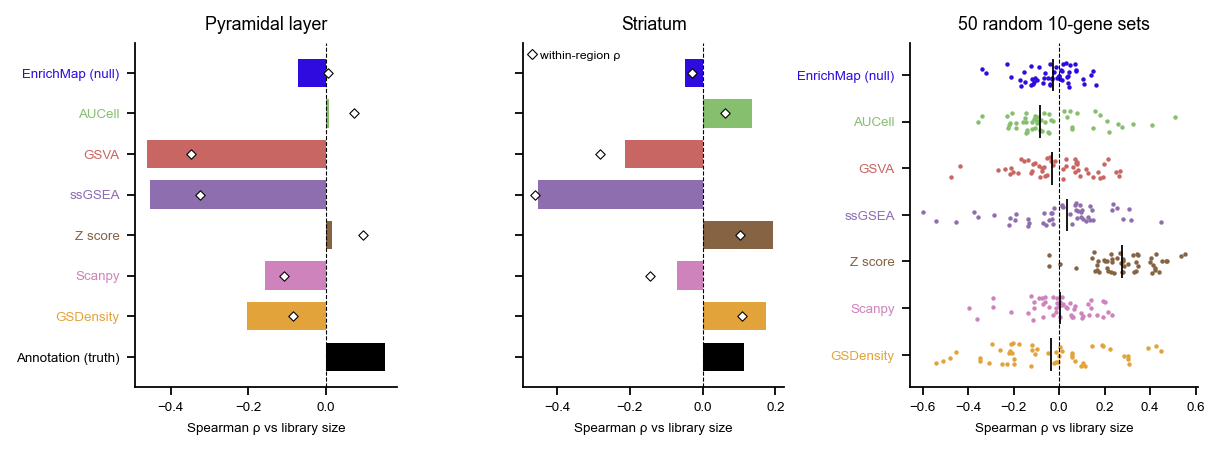

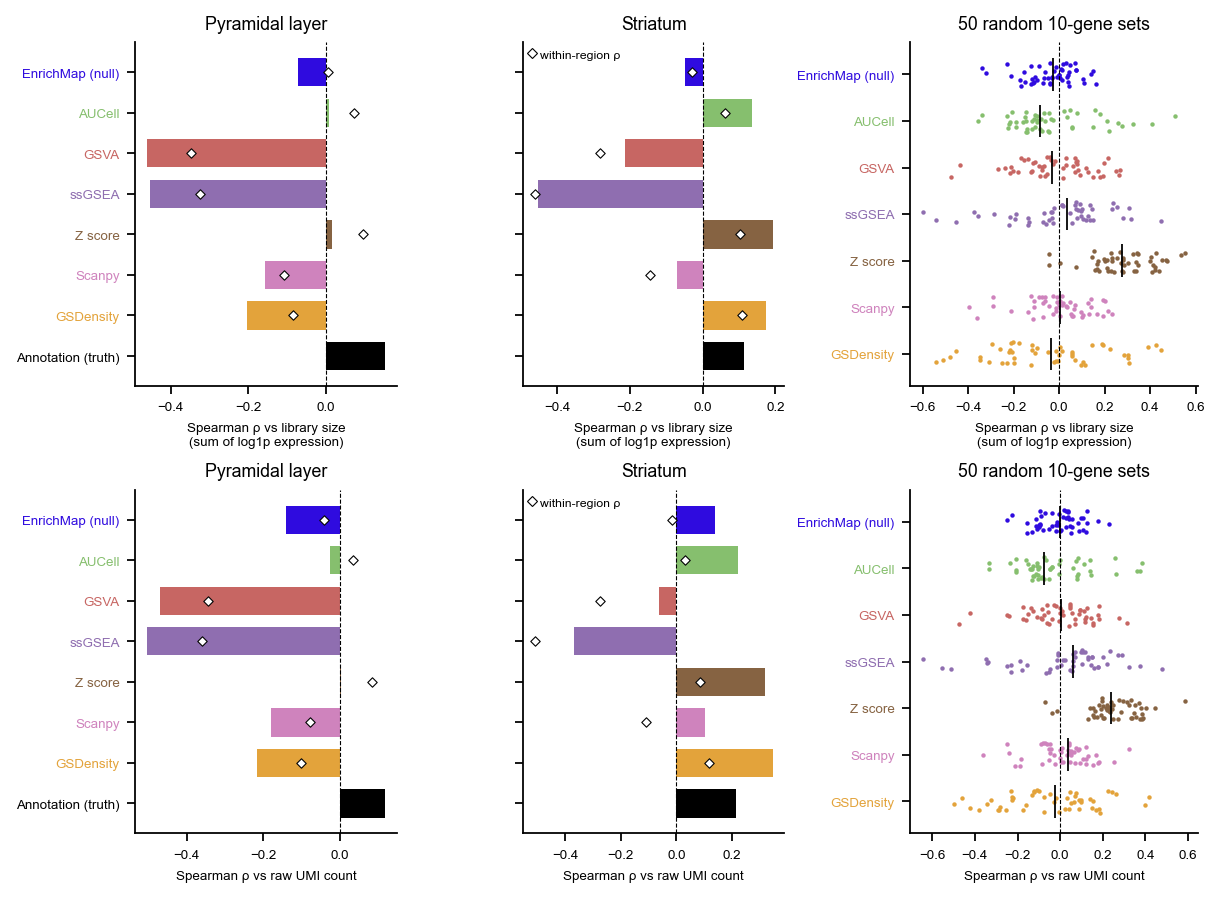

In [23]:
# 17. Sup. Fig. 4b figure: bars = ρ over all spots, diamonds = within-region ρ; random sets
fig, axes = plt.subplots(1, 3, figsize=(7.6, 2.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
plot_library_size_dependence(axes, lib, lib_random, regions, region_labels, colours, lib_col,
                             "within-region ρ library size", lib_col, "Spearman ρ vs library size", truth=truth)
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig4b_library_size.pdf", bbox_inches="tight")
plt.show()

# full version: also against raw UMI counts (total_counts)
fig, axes = plt.subplots(2, 3, figsize=(7.6, 5.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
plot_library_size_dependence(axes[0], lib, lib_random, regions, region_labels, colours, lib_col,
                             "within-region ρ library size", lib_col,
                             "Spearman ρ vs library size\n(sum of log1p expression)", truth=truth)
plot_library_size_dependence(axes[1], lib, lib_random, regions, region_labels, colours, "ρ total_counts",
                             "within-region ρ total_counts", "ρ total_counts", "Spearman ρ vs raw UMI count",
                             truth=truth)
plt.tight_layout()
plt.show()

lib.to_csv(source_dir + "ExtendedDataFig4b_library_size.csv", index=False)
lib_random.to_csv(source_dir + "ExtendedDataFig4b_library_size_random_sets.csv", index=False)

# per-spot scores and library size behind Sup. Fig. 4a-b
per_spot = maps_a[["spot_id", "x", "y", "cluster"]].copy()
per_spot["library_size_sum_log1p"] = lib_size
per_spot["total_counts_raw"] = total_counts
for ct in regions:
    for m in methods:
        per_spot[f"{region_labels[ct]} | {m}"] = s4[m][ct].values
    for k in ["null_mean", "null_sd", "p_empirical"]:
        per_spot[f"{region_labels[ct]} | {null} {k}"] = adata.uns["null_model"][f"{ct}_null"][k]


                  AUROC, contaminated  AUPRC, contaminated  ρ with clean score  ρ with housekeeping score  Moran's I, contaminated  |ρ| library size  |ρ| library size, within regions  |ρ| library size, random sets
method                                                                                                                                                                                                               
EnrichMap (null)                0.995                0.623               0.884                      0.317                    0.881             0.060                             0.017                          0.069
AUCell                          0.857                0.165               0.138                      0.971                    0.232             0.071                             0.067                          0.141
GSVA                            0.984                0.661               0.322                      0.888                    0.281             0

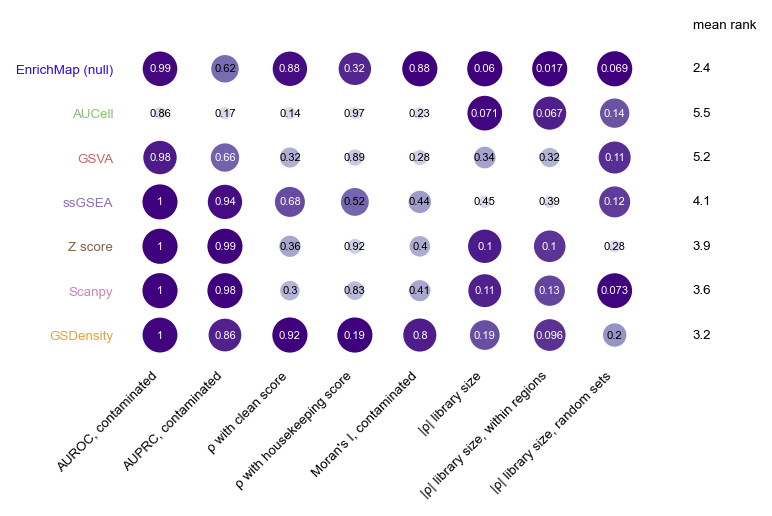

In [24]:
# 18. Summary panel: specificity and technical confounding, one row per method
clean, contam = "Spearman ρ with clean score", "Spearman ρ with housekeeping score"
combined = s3a_metrics[s3a_metrics["gene set"] == "combined"].rename(columns={
    "Spearman ρ vs pyramidal score": clean, "Spearman ρ vs housekeeping score": contam,
}).reset_index(drop=True)
by_method = lib[lib["method"] != truth].groupby("method", sort=False)
comb = combined.set_index("method")
summary = pd.DataFrame({
    "AUROC, contaminated": comb["AUROC"],
    "AUPRC, contaminated": comb["AUPRC"],
    "ρ with clean score": comb[clean],
    "ρ with housekeeping score": comb[contam],
    "Moran's I, contaminated": comb["Moran's I"],
    "|ρ| library size": by_method[lib_col].apply(lambda x: x.abs().mean()),
    "|ρ| library size, within regions": by_method["within-region ρ library size"].apply(lambda x: x.abs().mean()),
    "|ρ| library size, random sets": lib_random_summary["median_abs"],
}).loc[methods]
print(summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(4.8, 3.2))
plot_method_summary_dots(summary, ax, colours, lower_is_better=("ρ with housekeeping score", "|ρ| library size",
                                                                "|ρ| library size, within regions",
                                                                "|ρ| library size, random sets"))
ax.tick_params(labelsize=6, length=0)
plt.tight_layout()
plt.show()
